# Faktenretention

**Ziel dieses Notebooks**

Dieses Notebook hat als Ziel die Forschungsfragen **F1** und **F2** zu beantworten.

Dabei geht es zum einen um die Faktenretention entlang der rekursiven Kompressionskette und zum anderen um den gepaarten Methodenvergleich verschiedener Methodenpaare.

Die Auswertung wird vollständig aus gespeicherten Einzelantworten neu berechnet. Es erfolgen keine neuen Modellaufrufe. Der kanonische Faktensatz bleibt über alle Methoden und Stufen gleich. Technisch fehlende QA-Urteile werden separat geführt. Bootstrap-Einheit ist der **Artikel**, nicht die einzelne Frage oder Zusammenfassung.

Die tatsächliche Wortlänge und längenadjustierte Retention gehören in die folgenden Auswertungen. Die hier berichteten Unterschiede gelten für die erzeugten Texte bei denselben **Zielwortzahlen**, nicht zwingend derselben tatsächlichen Länge.

Abbildungen 8–10 und Tabellen 15/16/20.

In [1]:
from pathlib import Path
from fractions import Fraction
from collections import Counter
from itertools import combinations
import hashlib, importlib.metadata, json, math, platform, re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
from IPython.display import display
from threadpoolctl import threadpool_limits
from faktenretention.io import PROJECT_ROOT
from faktenretention.data import load_inputs, panel, length_values, reconstruct_qa, aggregate_articles, CELL, KEY
from faktenretention.protocol import METHODS, STAGES, WINDOWS, CONTRASTS, LABELS
threadpool_limits(limits=1)
SEED, B, N_FACTS = (32, 10000, 20)
DATA_DIR = PROJECT_ROOT / 'data'
OUT = PROJECT_ROOT / 'results/02_faktenretention'
FIG = OUT
OUT.mkdir(parents=True, exist_ok=True)
COLORS = dict(zip(METHODS, ['#777777', '#0072B2', '#E69F00', '#009E73', '#CC79A7', '#D55E00']))
MARKERS = dict(zip(METHODS, ['o', 's', '^', 'D', 'v', 'P']))
LINESTYLES = dict(zip(METHODS, ['--', '-', '-.', '--', ':', '-']))
plt.rcParams.update({'figure.dpi': 110, 'font.size': 10, 'axes.spines.top': False, 'axes.spines.right': False})
pd.set_option('display.max_rows', 26)

def export(frame, name):
    frame.to_csv(OUT / f'{name}.csv', index=False)

def fmt(x, d=2):
    return f'{x:.{d}f}'.replace('.', ',')

def savefig(fig, name):
    fig.savefig(FIG / f'{name}.png', dpi=220, bbox_inches='tight')
    plt.show()
    plt.close(fig)

## Dateninitialisierung, Labelrekonstruktion und Artikelaggregation

Die gemeinsamen Funktionen prüfen kanonische Fakten und rekursive Eingaben, rekonstruieren den eingefrorenen Scorer und aggregieren K und V. Technische Fehlwerte zählen nicht als NOT_FOUND. Es gibt keinen gemessenen QA-Ausgangswert am Originalartikel.

In [2]:
inputs = load_inputs()
lengths = length_values(inputs)
qa = reconstruct_qa(inputs, lengths)
article = aggregate_articles(qa)
IDS = sorted(inputs['articles'].article_id)
status = qa.groupby(['method', 'stage_target_words', 'label']).size().unstack(fill_value=0)
display(status)
assert len(article) == 2400 and qa.analysis_eligible.sum() == 47804 and (qa.technical_missing.sum() == 196)
assert qa.loc[qa.empty_output, 'lost'].sum() == 40

label                             lost  reference_discordant  retained  \
method        stage_target_words                                         
auto_cot      75                   983                   234       781   
              150                  565                   269      1153   
              300                  382                   251      1356   
              500                  329                   240      1419   
automate_cot  75                  1033                   224       738   
              150                  662                   255      1074   
              300                  374                   239      1371   
              500                  312                   217      1460   
few_shot_cot  75                  1078                   226       688   
              150                  714                   263      1008   
              300                  501                   276      1216   
              500                  464                   246      1274   
lead_k        75                  1566                    87       346   
              150                 1286                   107       604   
              300                  911                   100       986   
              500                  400                    87      1508   
plain         75                  1090                   230       674   
              150                  841                   250       897   
              300                  745                   250       995   
              500                  670                   228      1092   
zero_shot_cot 75                  1227                   193       578   
              150                  673                   252      1071   
              300                  406                   234      1352   
              500                  346                   214      1433   

label                             technical_missing  
method        stage_target_words                     
auto_cot      75                                  2  
              150                                13  
              300                                11  
              500                                12  
automate_cot  75                                  5  
              150                                 9  
              300                                16  
              500                                11  
few_shot_cot  75                                  8  
              150                                15  
              300                                 7  
              500                                16  
lead_k        75                                  1  
              150                                 3  
              300                                 3  
              500                                 5  
plain         75                                  6  
              150                                12  
              300                                10  
              500                                10  
zero_shot_cot 75                                  2  
              150                                 4  
              300                                 8  
              500                                 7

## 4. F1: Verlauf über die Kompressionsstufen

Folgend werden Grafiken zur behandlung der Forschungsfrage F1 berechnet. Dabei geht es um die entwicklung der Faktenretention entlang der rekursiven Kompressionskette. bei 100% Faktenretention konnten alle Ausgangsfakten durch eine Zusammenfassung korrekt beantwortet werdenm, bei 0% wurde keine der Ausgangsfakten korrekt beantwortet. Die vertikalen Balken der punkte sind Bootstrap-Intervalle.

Technischer Prüfpunkt für den Autor: 100 % unter K/V beziehen sich auf die gültigen Urteile; nur V=20 belegt damit 20 von 20.

In [3]:
index_cache = {}
from faktenretention.statistics import estimate
from faktenretention.statistics import means_for
means = means_for(article)
means_percent = means.assign(mean_percent=100 * means['mean'], ci_low_percent=100 * means.ci_low, ci_high_percent=100 * means.ci_high)
export(means_percent, 'retention_mittelwerte_95ci')
mean_table = means.assign(method=lambda d: d.method.map(LABELS), Ergebnis=lambda d: [f'{fmt(100 * r.mean)} [{fmt(100 * r.ci_low)}; {fmt(100 * r.ci_high)}]; n={r.n_articles}' for r in d.itertuples()])
display(mean_table.pivot(index='method', columns='stage_target_words', values='Ergebnis').reindex(index=list(LABELS.values()), columns=STAGES))

stage_target_words,500,300,150,75
method,,,,
Lead-k,"75,59 [72,83; 78,26]; n=100","49,37 [46,68; 52,04]; n=100","30,24 [27,98; 32,51]; n=100","17,31 [15,60; 19,05]; n=100"
Plain,"54,89 [51,53; 58,11]; n=100","50,01 [46,65; 53,26]; n=100","45,11 [41,86; 48,25]; n=100","33,80 [30,95; 36,71]; n=100"
Zero-Shot-CoT,"71,89 [69,14; 74,60]; n=100","67,85 [65,09; 70,55]; n=100","53,63 [50,52; 56,68]; n=100","28,93 [26,14; 31,77]; n=100"
Few-Shot-CoT,"64,19 [61,21; 67,03]; n=100","61,04 [58,06; 63,97]; n=100","50,83 [47,74; 53,80]; n=100","34,55 [31,67; 37,49]; n=100"
Auto-CoT,"71,34 [68,61; 73,93]; n=100","68,16 [65,37; 70,84]; n=100","58,00 [54,93; 60,99]; n=100","39,08 [36,44; 41,70]; n=100"
Automate-CoT,"73,38 [70,60; 76,07]; n=100","69,12 [66,32; 71,81]; n=100","53,95 [50,74; 57,08]; n=100","36,99 [34,06; 39,95]; n=100"


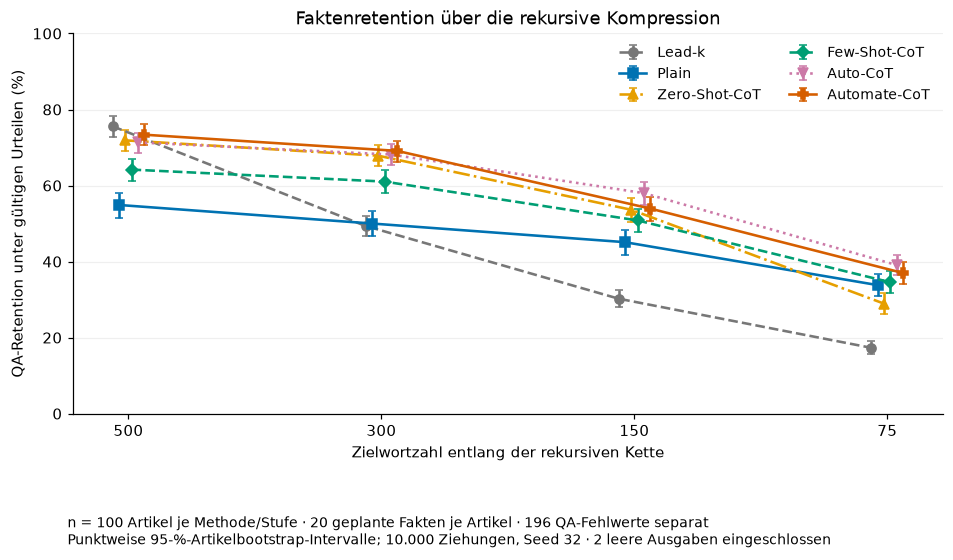

,method,transition,from_stage,to_stage,n_articles,mean,ci_low,ci_high,n_increase,n_equal,n_decrease
0,lead_k,500→300,500,300,100,-26.218421,-28.510526,-23.920921,1,0,99
1,lead_k,300→150,300,150,100,-19.126316,-21.018421,-17.247303,0,5,95
2,lead_k,150→75,150,75,100,-12.934211,-14.634276,-11.313158,0,10,90
3,lead_k,500→75,500,75,100,-58.278947,-60.878947,-55.592105,0,0,100
4,plain,500→300,500,300,100,-4.880994,-6.456155,-3.405526,8,39,53
5,plain,300→150,300,150,100,-4.902047,-6.426082,-3.498787,2,52,46
6,plain,150→75,150,75,100,-11.308187,-13.787105,-8.981455,2,27,71
7,plain,500→75,500,75,100,-21.091228,-23.979569,-18.293246,1,5,94
8,zero_shot_cot,500→300,500,300,100,-4.034795,-5.566433,-2.578860,11,41,48
9,zero_shot_cot,300→150,300,150,100,-14.221930,-16.880768,-11.755263,2,14,84


,method,transition,mean,ci_low,ci_high,n_articles
18,auto_cot,150→75,-18.928363,-21.115855,-16.800000,100
22,automate_cot,150→75,-16.963158,-18.990797,-14.923677,100
14,few_shot_cot,150→75,-16.277468,-18.335678,-14.233016,100
0,lead_k,500→300,-26.218421,-28.510526,-23.920921,100
6,plain,150→75,-11.308187,-13.787105,-8.981455,100
10,zero_shot_cot,150→75,-24.705263,-27.065921,-22.397368,100


In [4]:
fig, ax = plt.subplots(figsize=(10.2, 5.4))
x = np.arange(4)
for i, method in enumerate(METHODS):
    sub = means[means.method.eq(method)].set_index('stage_target_words').loc[STAGES]
    offset = (i - 2.5) * 0.025
    y = 100 * sub['mean'].to_numpy()
    err = np.vstack([y - 100 * sub.ci_low.to_numpy(), 100 * sub.ci_high.to_numpy() - y])
    ax.errorbar(x + offset, y, yerr=err, color=COLORS[method], marker=MARKERS[method], linestyle=LINESTYLES[method],
        linewidth=1.7, capsize=2.5, label=LABELS[method])
ax.set(xticks=x, xticklabels=STAGES, ylim=(0, 100), yticks=np.arange(0, 101, 20), xlabel='Zielwortzahl entlang der rekursiven Kette',
    ylabel='QA-Retention unter gültigen Urteilen (%)', title='Faktenretention über die rekursive Kompression')
ax.grid(axis='y', alpha=0.2)
ax.legend(loc='upper right', ncol=2, frameon=False, fontsize=9)
fig.subplots_adjust(bottom=0.24)
fig.text(0.12, 0.02, f'n = 100 Artikel je Methode/Stufe · 20 geplante Fakten je Artikel · {qa.technical_missing.sum()} QA-Fehlwerte separat\nPunktweise 95-%-Artikelbootstrap-Intervalle; 10.000 Ziehungen, Seed 32 · 2 leere Ausgaben eingeschlossen', fontsize=9)
savefig(fig, 'abb_08_retentionsverlauf')
TRANSITIONS = [(500, 300), (300, 150), (150, 75), (500, 75)]
change_rows = []
for method in METHODS:
    wide = article[article.method.eq(method)].pivot(index='article_id', columns='stage_target_words',
        values='retention_observed')
    for before, after in TRANSITIONS:
        diff = 100 * (wide[after] - wide[before])
        change_rows.append({'method': method, 'transition': f'{before}→{after}', 'from_stage': before,
            'to_stage': after, **estimate(diff), 'n_increase': int(diff.gt(1e-12).sum()), 'n_equal': int(diff.abs().le(1e-12).sum()),
            'n_decrease': int(diff.lt(-1e-12).sum())})
changes = pd.DataFrame(change_rows)
export(changes, 'stufenaenderungen_pp_95ci')
display(changes)
adjacent = changes[changes.transition.ne('500→75')]
steepest = adjacent.loc[adjacent.groupby('method')['mean'].idxmin(), ['method', 'transition', 'mean',
    'ci_low', 'ci_high', 'n_articles']]
display(steepest)

## 5. F2: vier gepaarte Methodenvergleiche

Folgend wird auf F2 eingegangen. Dabei werden die Methodenpaare verglichen welche in Kapitel 1.2 der Arbeit definiert wurden. Hierfür wird stets die mittlere Faktenretention berechnet.

Einheitliche Richtung: **erstgenannte minus zweitgenannte Methode**. Positive Werte begünstigen die erstgenannte Methode. Berichtet wird die mittlere artikelweise Differenz in **Prozentpunkten**, mit punktweisem 95-%-Intervall und Zahl gültiger Paare. Lead-k bleibt eine beschreibende Baseline außerhalb dieser vier Kontraste.

Beim größten mittleren Rückgang ist zu beachten, dass der Rückgang von 800 auf 500 Wörter nicht aufgeführt wird obwohl dieser an sich den größten Rückgang beherbergt. Grund dafür ist, dass keine Werte darüber bestehen wie viele der Fakten von dem QA-Eval model und Scorer im ursprünglichen Dokument als retained markiert würden, obwohl dort alle beinhaltet sein müssten.

Technischer Prüfpunkt für den Autor: Original-QA wurde nicht gemessen. Ein Rückgang vom Original zur ersten Stufe kann deshalb nicht quantifiziert werden.

stage_target_words,500,300,150,75
contrast,,,,
Zero-Shot-CoT − Plain,"17,00 [14,29; 19,77]; n=100","17,84 [15,11; 20,57]; n=100","8,52 [5,59; 11,33]; n=100","-4,87 [-7,57; -2,25]; n=100"
Few-Shot-CoT − Plain,"9,30 [6,75; 11,88]; n=100","11,03 [8,51; 13,57]; n=100","5,72 [3,28; 8,15]; n=100","0,75 [-1,68; 3,17]; n=100"
Auto-CoT − Few-Shot-CoT,"7,15 [4,89; 9,48]; n=100","7,12 [4,98; 9,32]; n=100","7,18 [4,54; 9,83]; n=100","4,53 [2,17; 6,88]; n=100"
Automate-CoT − Auto-CoT,"2,04 [0,08; 4,02]; n=100","0,96 [-1,13; 2,98]; n=100","-4,05 [-6,50; -1,67]; n=100","-2,09 [-4,46; 0,32]; n=100"


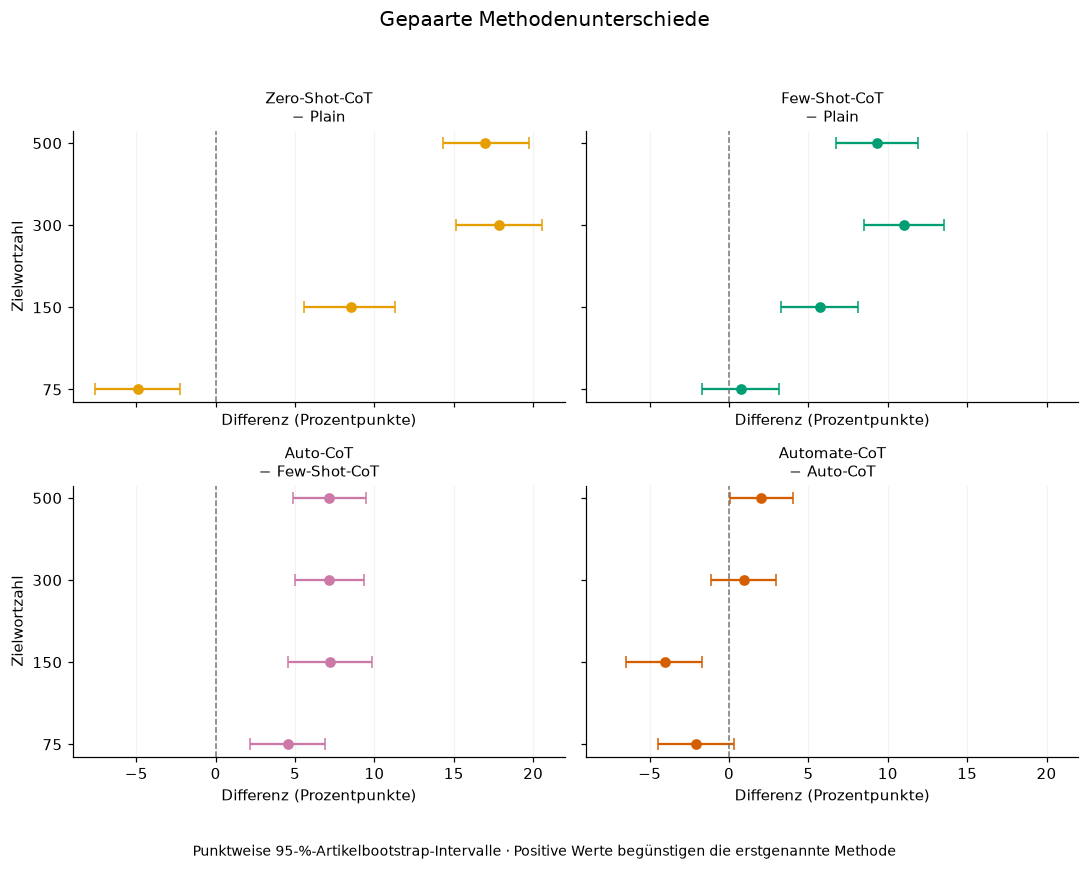

In [5]:
from faktenretention.statistics import contrasts_for
contrasts = contrasts_for(article)
assert len(contrasts) == 16 and contrasts.n_articles.eq(100).all()
export(contrasts, 'vier_gepaarte_kontraste_pp_95ci')
contrast_table = contrasts.assign(Ergebnis=[f'{fmt(r.mean)} [{fmt(r.ci_low)}; {fmt(r.ci_high)}]; n={r.n_articles}' for r in contrasts.itertuples()])
contrast_table = contrast_table.pivot(index='contrast', columns='stage_target_words', values='Ergebnis').reindex(index=[f'{LABELS[a]} − {LABELS[b]}' for a,
    b in CONTRASTS], columns=STAGES)
display(contrast_table)
contrast_table.to_csv(OUT / 'tabelle_kontraste_formatiert.csv')
fig, axes = plt.subplots(2, 2, figsize=(10, 8), sharey=True, sharex=True)
for ax, (first, second) in zip(axes.flat, CONTRASTS):
    sub = contrasts[(contrasts['first'] == first) & (contrasts.second == second)].set_index('stage_target_words').loc[STAGES]
    y = np.arange(4)
    ax.errorbar(sub['mean'], y, xerr=np.vstack([sub['mean'] - sub.ci_low, sub.ci_high - sub['mean']]),
        fmt='o', color=COLORS[first], capsize=4, markersize=6)
    ax.axvline(0, color='#777777', linestyle='--', linewidth=1)
    ax.set_title(f'{LABELS[first]}\n− {LABELS[second]}', fontsize=10)
    ax.set_xlabel('Differenz (Prozentpunkte)')
    ax.grid(axis='x', alpha=0.15)
for ax in axes[:, 0]:
    ax.set(yticks=np.arange(4), yticklabels=STAGES, ylabel='Zielwortzahl')
axes[0, 0].invert_yaxis()
fig.suptitle('Gepaarte Methodenunterschiede', fontsize=13)
fig.text(0.5, 0.02, 'Punktweise 95-%-Artikelbootstrap-Intervalle · Positive Werte begünstigen die erstgenannte Methode',
    fontsize=9, ha='center')
fig.tight_layout(rect=(0, 0.06, 1, 0.95))
savefig(fig, 'abb_10_gepaarte_kontraste')

## 6. Verteilungen auf Artikelebene

Die folgende Grafik zeigt die Faktenretention einzelner Artikel zwischen den Verfahren.

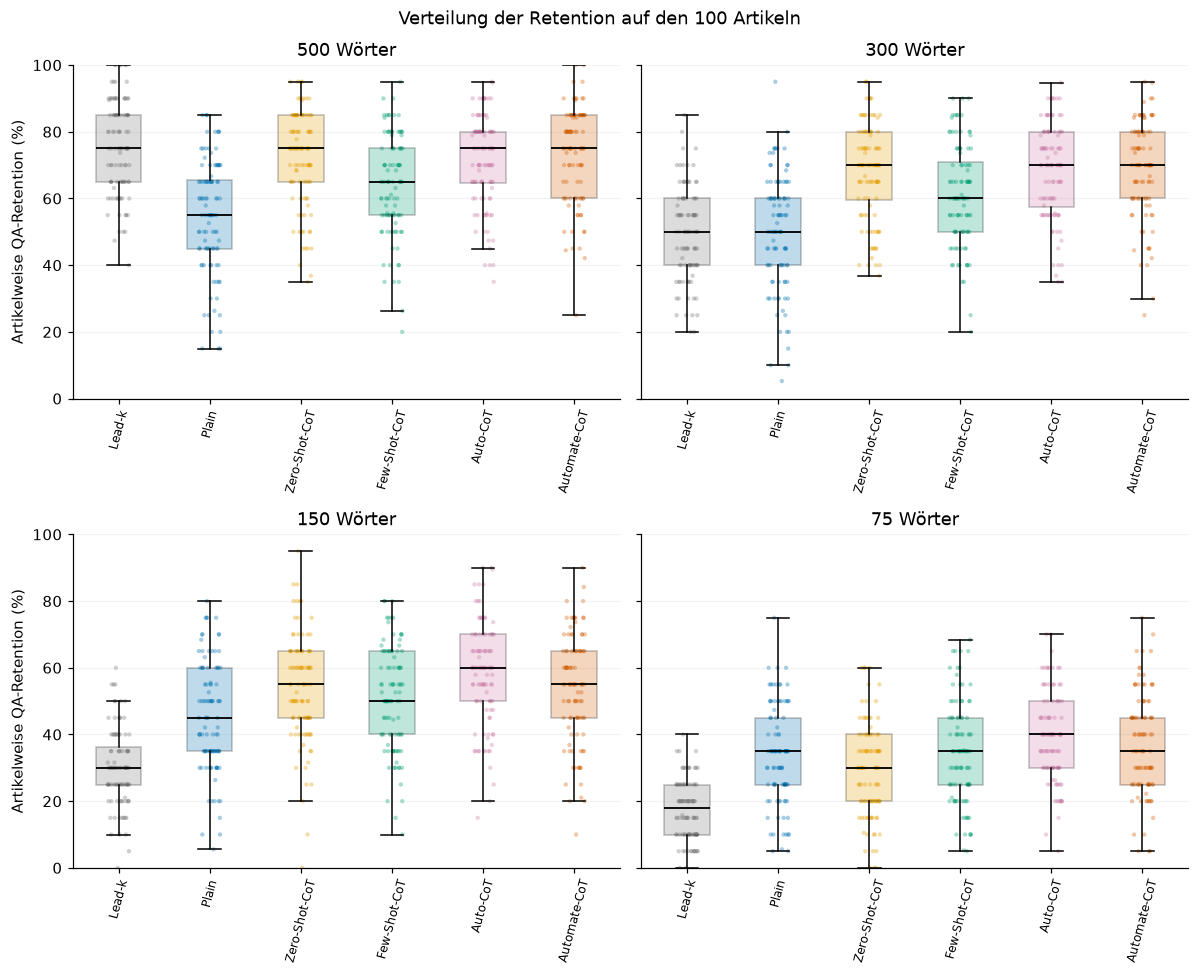

In [6]:
fig, axes = plt.subplots(2, 2, figsize=(11, 9), sharey=True)
jitter = np.random.default_rng(SEED).uniform(-0.12, 0.12, size=len(IDS))
for ax, stage in zip(axes.flat, STAGES):
    arrays = [100 * article[(article.method == m) & (article.stage_target_words == stage)].sort_values('article_id').retention_observed.to_numpy() for m in METHODS]
    boxes = ax.boxplot(arrays, positions=np.arange(6), widths=0.5, patch_artist=True, showfliers=False,
        medianprops={'color': 'black', 'linewidth': 1.2})
    for i, (method, values) in enumerate(zip(METHODS, arrays)):
        boxes['boxes'][i].set_facecolor(COLORS[method])
        boxes['boxes'][i].set_alpha(0.25)
        ax.scatter(i + jitter, values, s=8, color=COLORS[method], alpha=0.35, edgecolors='none')
    ax.set(title=f'{stage} Wörter', xticks=np.arange(6), xticklabels=[LABELS[m] for m in METHODS], ylim=(0, 100))
    ax.tick_params(axis='x', labelrotation=75, labelsize=8)
    ax.grid(axis='y', alpha=0.15)
for ax in axes[:, 0]:
    ax.set_ylabel('Artikelweise QA-Retention (%)')
fig.suptitle('Verteilung der Retention auf den 100 Artikeln')
fig.tight_layout()
savefig(fig, 'abb_09_artikelverteilungen')

## Technische Fehlwerte: K/V gegenüber K/20

In [7]:
sensitivity = article.groupby(['method', 'stage_target_words'])[['retention_observed', 'retention_lower',
    'n_missing']].mean().reset_index()
sensitivity['difference_pp'] = 100 * (sensitivity.retention_observed - sensitivity.retention_lower)
for stage, group in sensitivity.groupby('stage_target_words'):
    assert group.retention_observed.rank().eq(group.retention_lower.rank()).all()
assert sensitivity.difference_pp.max() < 0.58
export(sensitivity, 'nennervergleich_k_v_k_20')
display(sensitivity)

,method,stage_target_words,retention_observed,retention_lower,n_missing,difference_pp
0,auto_cot,75,0.390763,0.3905,0.02,0.026316
1,auto_cot,150,0.580047,0.5765,0.13,0.354678
2,auto_cot,300,0.681620,0.6780,0.11,0.361988
3,auto_cot,500,0.713371,0.7095,0.12,0.387135
4,automate_cot,75,0.369906,0.3690,0.05,0.090643
5,automate_cot,150,0.539538,0.5370,0.09,0.253801
6,automate_cot,300,0.691184,0.6855,0.16,0.568421
7,automate_cot,500,0.733760,0.7300,0.11,0.376023
8,few_shot_cot,75,0.345503,0.3440,0.08,0.150310
9,few_shot_cot,150,0.508278,0.5040,0.15,0.427778


## Tabelle 20: Minimale hypothetische Labeländerungen

Gültige Urteile der beiden verglichenen Verfahren bilden den Bezugsnenner. Pro Änderung beträgt der Einfluss 100/(100·V) Prozentpunkte. Absteigende Gewichte liefern die minimale Anzahl bis zur **strikten** Vorzeichenumkehr; geprüft mit exakten rationalen Zahlen. Keine simulierte Fehlerwahrscheinlichkeit.

In [8]:
article_lookup = article.set_index(CELL)
qa_candidates = qa.merge(article[CELL + ['n_valid']], on=CELL, validate='many_to_one')
attack_rows = []
for first, second in CONTRASTS:
    for stage in STAGES:
        difference = sum((Fraction(int(article_lookup.loc[a, first, stage].n_retained), int(article_lookup.loc[a,
            first, stage].n_valid)) - Fraction(int(article_lookup.loc[a, second, stage].n_retained),
            int(article_lookup.loc[a, second, stage].n_valid)) for a in IDS), Fraction(0)) * Fraction(100, len(IDS))
        sign = 1 if difference > 0 else -1
        pool = qa_candidates[qa_candidates.method.isin([first, second]) & qa_candidates.stage_target_words.eq(stage) & qa_candidates.analysis_eligible].copy()
        pool['new_label'] = np.where(pool.method.eq(first), sign < 0, sign > 0)
        pool = pool[pool.retained.ne(pool.new_label)].sort_values(['n_valid', 'article_id', 'method',
            'canonical_fact_id'])
        weights = [Fraction(100, len(IDS) * int(v)) for v in pool.n_valid]
        cumulative = Fraction(0)
        for k, w in enumerate(weights, 1):
            previous = cumulative
            cumulative += w
            if cumulative > abs(difference):
                break
        assert previous <= abs(difference) < cumulative
        selected = pool.head(k)
        delta = selected.assign(change=selected.new_label.astype(int) - selected.retained.astype(int)).groupby(['article_id',
            'method']).change.sum()
        after = sum((Fraction(int(article_lookup.loc[a, first, stage].n_retained) + int(delta.get((a,
            first), 0)), int(article_lookup.loc[a, first, stage].n_valid)) - Fraction(int(article_lookup.loc[a,
            second, stage].n_retained) + int(delta.get((a, second), 0)), int(article_lookup.loc[a, second,
            stage].n_valid)) for a in IDS), Fraction(0)) * Fraction(100, len(IDS))
        assert after == difference - sign * cumulative and after * difference < 0
        denominator = int(article.loc[article.method.isin([first, second]) & article.stage_target_words.eq(stage), 'n_valid'].sum())
        attack_rows.append(dict(first=first, second=second, stage_target_words=stage, original_difference_pp=float(difference),
            min_strict_reverse=k, valid_comparison_judgments=denominator, min_reverse_percent_valid=100 * k / denominator,
            difference_after_strict_reverse_pp=float(after)))
attacks = pd.DataFrame(attack_rows)
assert len(attacks) == 16
export(attacks, 'tabelle_20_minimale_labelaenderungen')
display(attacks.round(4))

,first,second,stage_target_words,original_difference_pp,min_strict_reverse,valid_comparison_judgments,min_reverse_percent_valid,difference_after_strict_reverse_pp
0,zero_shot_cot,plain,500,16.9968,332,3983,8.3354,-0.0500
1,zero_shot_cot,plain,300,17.8430,348,3982,8.7393,-0.0500
2,zero_shot_cot,plain,150,8.5231,163,3984,4.0914,-0.0500
3,zero_shot_cot,plain,75,-4.8740,95,3992,2.3798,0.0500
4,few_shot_cot,plain,500,9.2991,175,3974,4.4036,-0.0342
5,few_shot_cot,plain,300,11.0322,212,3983,5.3226,-0.0500
6,few_shot_cot,plain,150,5.7193,106,3973,2.6680,-0.0526
7,few_shot_cot,plain,75,0.7500,14,3986,0.3512,-0.0474
8,auto_cot,few_shot_cot,500,7.1465,134,3972,3.3736,-0.0289
9,auto_cot,few_shot_cot,300,7.1193,134,3982,3.3651,-0.0211
